# Linear and Ridge Regression

Cross-validation experiments for heating- and cooling-load prediction.

## Setup

Shared data tools and the libraries used for modeling and evaluation.

In [1]:
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make the shared src package importable
cwd = Path.cwd().resolve()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data import load_data, create_dev_test_split
from src.config import FEATURE_COLUMNS, TARGET_COLUMNS, N_FOLDS

print("Imports successful")

Imports successful


## Development data and cross-validation folds

The test set remains separate while the development set is divided into five folds.

In [2]:
df = load_data()

X_dev, X_test, y_dev, y_test = create_dev_test_split(df)

print("Development features:", X_dev.shape)
print("Development targets:", y_dev.shape)
print("Test features:", X_test.shape)
print("Test targets:", y_test.shape)

cv = KFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, val_idx) in enumerate(cv.split(X_dev), start=1):
    print(
        f"Fold {fold}: "
        f"{len(train_idx)} training, "
        f"{len(val_idx)} validation"
    )

Development features: (614, 8)
Development targets: (614, 2)
Test features: (154, 8)
Test targets: (154, 2)
Fold 1: 491 training, 123 validation
Fold 2: 491 training, 123 validation
Fold 3: 491 training, 123 validation
Fold 4: 491 training, 123 validation
Fold 5: 492 training, 122 validation


## One-fold example

One heating-load model, including its learned coefficients and validation error.

In [3]:
train_idx, val_idx = next(cv.split(X_dev))

X_train = X_dev.iloc[train_idx]
X_val = X_dev.iloc[val_idx]

y_train = y_dev["heating_load"].iloc[train_idx]
y_val = y_dev["heating_load"].iloc[val_idx]

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_val)

print("Intercept:", model.intercept_)

coefficients = pd.Series(
    model.coef_,
    index=FEATURE_COLUMNS
)

print(coefficients)

Intercept: 82.01129323647373
relative_compactness        -63.754937
surface_area                 -0.061393
wall_area                     0.037588
roof_area                    -0.049491
overall_height                4.146491
orientation                  -0.087611
glazing_area                 20.241286
glazing_area_distribution     0.252707
dtype: float64


In [4]:
mae = mean_absolute_error(y_val, predictions)
rmse = mean_squared_error(y_val, predictions) ** 0.5
r2 = r2_score(y_val, predictions)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

comparison = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Predicted": predictions,
    "Error": predictions - y_val.to_numpy()
})

comparison.head(10)

MAE:  1.953
RMSE: 2.807
R²:   0.928


,Actual,Predicted,Error
0,29.27,29.099198,-0.170802
1,35.96,32.882452,-3.077548
2,16.84,14.871303,-1.968697
3,15.16,12.165302,-2.994698
4,33.28,34.083473,0.803473
5,14.17,14.535430,0.365430
6,32.68,30.109091,-2.570909
7,10.43,7.539828,-2.890172
8,24.40,25.083937,0.683937
9,12.72,12.422088,-0.297912


## Five-fold linear regression

The cross-validation experiment fits one model per fold for each target (10 fits).

In [5]:
results = []

for target in TARGET_COLUMNS:

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_dev), start=1
    ):

        X_train = X_dev.iloc[train_idx]
        X_val = X_dev.iloc[val_idx]

        y_train = y_dev[target].iloc[train_idx]
        y_val = y_dev[target].iloc[val_idx]

        # New model for every fold
        model = LinearRegression()

        # Time model training
        start = perf_counter()
        model.fit(X_train, y_train)
        train_time = perf_counter() - start

        # Time prediction
        start = perf_counter()
        predictions = model.predict(X_val)
        prediction_time = perf_counter() - start

        results.append({
            "target": target,
            "model": "linear",
            "n_features": len(FEATURE_COLUMNS),
            "fold": fold,
            "model_seed": None,
            "mae": mean_absolute_error(y_val, predictions),
            "rmse": mean_squared_error(y_val, predictions) ** 0.5,
            "r2": r2_score(y_val, predictions),
            "train_time": train_time,
            "prediction_time": prediction_time,
        })

results_df = pd.DataFrame(results)

results_df

,target,model,n_features,fold,model_seed,mae,rmse,r2,train_time,prediction_time
0,heating_load,linear,8,1,None,1.952503,2.807182,0.927563,0.003625,0.001164
1,heating_load,linear,8,2,None,2.207098,3.167539,0.901554,0.003029,0.001503
2,heating_load,linear,8,3,None,2.118423,2.999942,0.908954,0.002387,0.001156
3,heating_load,linear,8,4,None,1.967580,2.706379,0.927574,0.004776,0.002364
4,heating_load,linear,8,5,None,2.063500,2.898087,0.907392,0.004552,0.002149
5,cooling_load,linear,8,1,None,2.149245,3.111927,0.895794,0.002381,0.001065
6,cooling_load,linear,8,2,None,2.191851,3.183584,0.886431,0.002526,0.001073
7,cooling_load,linear,8,3,None,2.559847,3.555193,0.860769,0.002252,0.001003
8,cooling_load,linear,8,4,None,2.382436,3.224160,0.889331,0.002157,0.000954
9,cooling_load,linear,8,5,None,2.103277,3.039817,0.882189,0.002256,0.001061


## Cross-validation summary

Bars show the fold means; error bars show one standard deviation.

mae          rmse            r2       
               mean    std   mean    std   mean    std
target                                                
heating_load  2.062  0.106  2.916  0.178  0.915  0.012
cooling_load  2.277  0.190  3.223  0.199  0.883  0.013

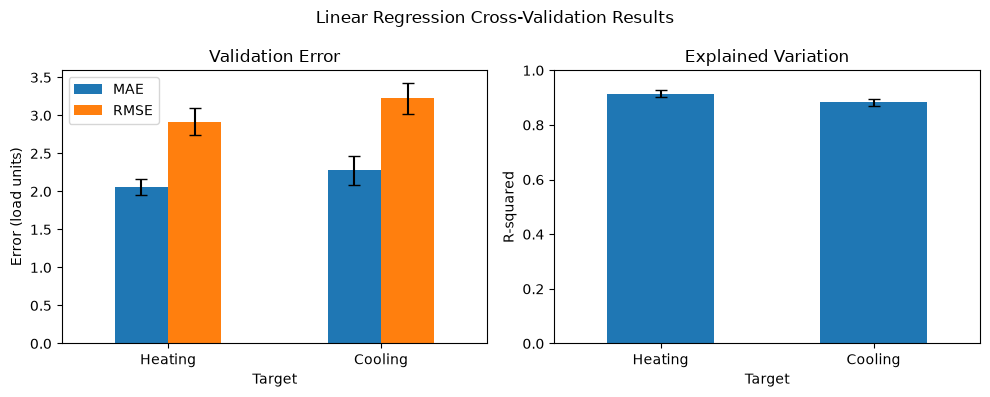

In [6]:
summary = results_df.groupby("target")[
    ["mae", "rmse", "r2"]
].agg(["mean", "std"]).loc[TARGET_COLUMNS]

display(summary.round(3))

mean_scores = results_df.groupby("target")[["mae", "rmse", "r2"]].mean().loc[TARGET_COLUMNS]
std_scores = results_df.groupby("target")[["mae", "rmse", "r2"]].std().loc[TARGET_COLUMNS]
target_labels = ["Heating", "Cooling"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

mean_scores[["mae", "rmse"]].plot.bar(
    yerr=std_scores[["mae", "rmse"]],
    capsize=4,
    rot=0,
    ax=axes[0],
)
axes[0].set_title("Validation Error")
axes[0].set_xlabel("Target")
axes[0].set_ylabel("Error (load units)")
axes[0].set_xticklabels(target_labels)
axes[0].legend(["MAE", "RMSE"])

mean_scores[["r2"]].plot.bar(
    yerr=std_scores[["r2"]],
    capsize=4,
    rot=0,
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Explained Variation")
axes[1].set_xlabel("Target")
axes[1].set_ylabel("R-squared")
axes[1].set_xticklabels(target_labels)
axes[1].set_ylim(0, 1)

fig.suptitle("Linear Regression Cross-Validation Results")
fig.tight_layout()
plt.show()

## Baseline review

- **Heating versus cooling:** Cooling is somewhat harder to predict, but the difference is not substantial. Its mean MAE and RMSE are about 10% higher than heating's, while mean R-squared is 0.883 compared with 0.915 for heating.
- **Consistency across folds:** Performance is reasonably consistent. Heating R-squared ranges from 0.902 to 0.928, and cooling ranges from 0.861 to 0.896. Cooling fold 3 is the weakest result (MAE 2.560, RMSE 3.555, R-squared 0.861), but it is not an extreme outlier.
- **Baseline quality:** Linear regression provides a sensible baseline. It explains about 91% of the heating-load variation and 88% of the cooling-load variation, leaving a useful benchmark for Ridge and Random Forest.
- **Timing:** Training and prediction take only a few milliseconds, so overhead and normal system activity create substantial relative noise. These measurements show that linear regression is fast, but repeated timings would be needed for precise comparisons between similarly fast models.
- **Correlated predictors:** Several architectural features are strongly related. Relative compactness and surface area have a correlation of -0.992, while roof area and overall height have a correlation of -0.973. Surface area also equals wall area plus twice the roof area in this dataset. This multicollinearity can make individual linear coefficients unstable or difficult to interpret even when predictions remain accurate. Ridge regression is the next experiment because its coefficient penalty is designed to reduce this instability.

## Fold-level results

Saved for later comparison with Ridge and Random Forest results.

In [7]:
output_path = project_root / "results" / "tables" / "linear_baseline_cv.csv"

output_path.parent.mkdir(parents=True, exist_ok=True)

results_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: C:\Senior Year\ELEG405\eleg405-energy-load-prediction\results\tables\linear_baseline_cv.csv


## Initial Ridge regression

Evaluate Ridge with `alpha=1.0` using the same development folds as the linear baseline.

In [8]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

### Ridge pipeline

Standardize each training fold before fitting Ridge so the penalty is applied consistently without validation-data leakage.

In [9]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

### Five-fold evaluation

Fit Ridge for both targets across the same five validation folds used by linear regression.

In [10]:
ridge_results = []

for target in TARGET_COLUMNS:

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_dev), start=1
    ):
        X_train = X_dev.iloc[train_idx]
        X_val = X_dev.iloc[val_idx]

        y_train = y_dev[target].iloc[train_idx]
        y_val = y_dev[target].iloc[val_idx]

        # Fresh pipeline for each fold
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=1.0)),
        ])

        # Time fitting, including scaling
        start = perf_counter()
        model.fit(X_train, y_train)
        train_time = perf_counter() - start

        # Time prediction, including scaling
        start = perf_counter()
        predictions = model.predict(X_val)
        prediction_time = perf_counter() - start

        ridge_results.append({
            "target": target,
            "model": "ridge",
            "n_features": 8,
            "fold": fold,
            "model_seed": None,
            "mae": mean_absolute_error(y_val, predictions),
            "rmse": mean_squared_error(y_val, predictions) ** 0.5,
            "r2": r2_score(y_val, predictions),
            "train_time": train_time,
            "prediction_time": prediction_time,
        })

ridge_results_df = pd.DataFrame(ridge_results)
ridge_results_df

,target,model,n_features,fold,model_seed,mae,rmse,r2,train_time,prediction_time
0,heating_load,ridge,8,1,None,1.948367,2.803734,0.927741,0.014388,0.002276
1,heating_load,ridge,8,2,None,2.205098,3.163777,0.901788,0.004766,0.001549
2,heating_load,ridge,8,3,None,2.103944,3.000090,0.908945,0.004817,0.001428
3,heating_load,ridge,8,4,None,1.975944,2.729299,0.926342,0.004131,0.001358
4,heating_load,ridge,8,5,None,2.066866,2.896513,0.907492,0.004740,0.001403
5,cooling_load,ridge,8,1,None,2.160015,3.107007,0.896124,0.004761,0.002259
6,cooling_load,ridge,8,2,None,2.177796,3.178369,0.886803,0.006570,0.001434
7,cooling_load,ridge,8,3,None,2.551505,3.559776,0.860410,0.004930,0.001428
8,cooling_load,ridge,8,4,None,2.396373,3.243140,0.888024,0.004101,0.001333
9,cooling_load,ridge,8,5,None,2.120378,3.041900,0.882027,0.004395,0.001338


### Initial Ridge comparison

Compare mean validation performance for linear regression and Ridge with `alpha=1.0`.

In [11]:
comparison_df = pd.concat(
    [results_df, ridge_results_df],
    ignore_index=True
)

summary = (
    comparison_df
    .groupby(["target", "model"])[["mae", "rmse", "r2"]]
    .agg(["mean", "std"])
)

summary.round(3)

mae          rmse            r2       
                      mean    std   mean    std   mean    std
target       model                                           
cooling_load linear  2.277  0.190  3.223  0.199  0.883  0.013
             ridge   2.281  0.185  3.226  0.201  0.883  0.013
heating_load linear  2.062  0.106  2.916  0.178  0.915  0.012
             ridge   2.060  0.103  2.919  0.170  0.914  0.012

In [12]:
mean_rmse = (
    comparison_df
    .groupby(["target", "model"])["rmse"]
    .mean()
    .unstack()
)

mean_rmse["ridge_minus_linear"] = (
    mean_rmse["ridge"] - mean_rmse["linear"]
)

mean_rmse.round(4)

model,linear,ridge,ridge_minus_linear
target,,,
cooling_load,3.2229,3.2260,0.0031
heating_load,2.9158,2.9187,0.0029


### Saved initial Ridge results

Store the fold-level `alpha=1.0` results for later model comparisons.

In [13]:
output_path = project_root / "results" / "tables" / "ridge_initial_cv.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

ridge_results_df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(ridge_results_df))

Saved: C:\Senior Year\ELEG405\eleg405-energy-load-prediction\results\tables\ridge_initial_cv.csv
Rows: 10


### Standardized Ridge coefficients

Inspect the first-fold heating coefficients after scaling. These magnitudes are not directly comparable with the earlier unscaled linear coefficients.

In [14]:
train_idx, val_idx = next(cv.split(X_dev))

X_train = X_dev.iloc[train_idx]
y_train = y_dev["heating_load"].iloc[train_idx]

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0)),
])

model.fit(X_train, y_train)

ridge_coefficients = pd.Series(
    model.named_steps["model"].coef_,
    index=FEATURE_COLUMNS
)

ridge_coefficients

relative_compactness        -5.341374
surface_area                -2.760724
wall_area                    1.014196
roof_area                   -3.196141
overall_height               7.585335
orientation                 -0.095945
glazing_area                 2.719750
glazing_area_distribution    0.390584
dtype: float64

## Ridge alpha tuning

Use nested cross-validation to select alpha without using the outer validation fold during tuning.

In [15]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

### Candidate alpha values

Test five penalty strengths using three-fold inner cross-validation and select the lowest-RMSE option.

In [16]:
RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0]

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge()),
])

param_grid = {
    "model__alpha": RIDGE_ALPHAS
}

inner_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

### One-fold tuning example

Demonstrate alpha selection inside the first outer training fold before evaluating its held-out validation rows.

In [17]:
train_idx, val_idx = next(cv.split(X_dev))

X_train = X_dev.iloc[train_idx]
X_val = X_dev.iloc[val_idx]

y_train = y_dev["heating_load"].iloc[train_idx]
y_val = y_dev["heating_load"].iloc[val_idx]

search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=inner_cv,
    refit=True,
)

search.fit(X_train, y_train)

print("Selected alpha:", search.best_params_)
print("Inner CV RMSE:", -search.best_score_)

predictions = search.predict(X_val)

print("Outer validation RMSE:",
      mean_squared_error(y_val, predictions) ** 0.5)

Selected alpha: {'model__alpha': 0.01}
Inner CV RMSE: 2.993272158387873
Outer validation RMSE: 2.8070964332940043


### Nested cross-validation

Repeat the inner alpha search within every outer fold for both prediction targets.

In [18]:
tuned_results = []

for target in TARGET_COLUMNS:

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_dev), start=1
    ):

        X_train = X_dev.iloc[train_idx]
        X_val = X_dev.iloc[val_idx]

        y_train = y_dev[target].iloc[train_idx]
        y_val = y_dev[target].iloc[val_idx]

        search = GridSearchCV(
            estimator=ridge_pipeline,
            param_grid=param_grid,
            scoring="neg_root_mean_squared_error",
            cv=inner_cv,
            refit=True,
        )

        start = perf_counter()
        search.fit(X_train, y_train)
        total_search_time = perf_counter() - start

        start = perf_counter()
        predictions = search.predict(X_val)
        prediction_time = perf_counter() - start

        tuned_results.append({
            "target": target,
            "model": "ridge_tuned",
            "n_features": 8,
            "fold": fold,
            "model_seed": None,
            "mae": mean_absolute_error(y_val, predictions),
            "rmse": mean_squared_error(y_val, predictions) ** 0.5,
            "r2": r2_score(y_val, predictions),
            "train_time": total_search_time,
            "prediction_time": prediction_time,
            "best_alpha": search.best_params_["model__alpha"],
            "inner_cv_rmse": -search.best_score_,
        })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df

,target,model,n_features,fold,model_seed,mae,rmse,r2,train_time,prediction_time,best_alpha,inner_cv_rmse
0,heating_load,ridge_tuned,8,1,None,1.952366,2.807096,0.927568,0.137236,0.001429,0.01,2.993272
1,heating_load,ridge_tuned,8,2,None,2.207016,3.167430,0.901561,0.127854,0.001401,0.01,2.866126
2,heating_load,ridge_tuned,8,3,None,2.116210,2.999435,0.908985,0.122848,0.001384,0.10,2.894658
3,heating_load,ridge_tuned,8,4,None,1.967591,2.706622,0.927561,0.123010,0.001745,0.01,2.966576
4,heating_load,ridge_tuned,8,5,None,2.063992,2.897916,0.907403,0.129894,0.001514,0.10,2.925146
5,cooling_load,ridge_tuned,8,1,None,2.149982,3.111190,0.895844,0.126312,0.001532,0.10,3.321628
6,cooling_load,ridge_tuned,8,2,None,2.191554,3.183417,0.886443,0.146978,0.001653,0.01,3.278675
7,cooling_load,ridge_tuned,8,3,None,2.557952,3.555363,0.860756,0.135001,0.001704,0.10,3.140106
8,cooling_load,ridge_tuned,8,4,None,2.382545,3.224336,0.889319,0.132998,0.001406,0.01,3.234628
9,cooling_load,ridge_tuned,8,5,None,2.103436,3.039816,0.882189,0.131821,0.001451,0.01,3.299739


### Selected alpha values

Count how often each penalty strength is selected across the outer folds.

In [19]:
tuned_results_df[
    ["target", "fold", "best_alpha", "inner_cv_rmse", "rmse"]
]
tuned_results_df.groupby(
    ["target", "best_alpha"]
).size()

target        best_alpha
cooling_load  0.01          3
              0.10          2
heating_load  0.01          3
              0.10          2
dtype: int64

### Final model comparison

Compare linear regression, Ridge with `alpha=1.0`, and nested-CV tuned Ridge.

In [20]:
all_results = pd.concat(
    [
        results_df,
        ridge_results_df,
        tuned_results_df,
    ],
    ignore_index=True
)

comparison = (
    all_results
    .groupby(["target", "model"])[["mae", "rmse", "r2"]]
    .agg(["mean", "std"])
)

comparison.round(4)

mae            rmse              r2        
                            mean     std    mean     std    mean     std
target       model                                                      
cooling_load linear       2.2773  0.1903  3.2229  0.1986  0.8829  0.0133
             ridge        2.2812  0.1855  3.2260  0.2013  0.8827  0.0134
             ridge_tuned  2.2771  0.1895  3.2228  0.1988  0.8829  0.0133
heating_load linear       2.0618  0.1062  2.9158  0.1778  0.9146  0.0121
             ridge        2.0600  0.1031  2.9187  0.1705  0.9145  0.0118
             ridge_tuned  2.0614  0.1060  2.9157  0.1776  0.9146  0.0121

### Saved tuned Ridge results

Store the selected alpha and outer-fold metrics for later comparison with other models.

In [21]:
output_path = (
    project_root / "results" / "tables" / "ridge_tuned_cv.csv"
)

tuned_results_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: C:\Senior Year\ELEG405\eleg405-energy-load-prediction\results\tables\ridge_tuned_cv.csv


## Feature availability experiments

Compare model performance when only the top 2, 4, 6, or all 8 predictors are available.

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from time import perf_counter

from src.features import make_selector
from src.config import (
    FEATURE_COLUMNS,
    TARGET_COLUMNS,
    FEATURE_COUNTS,
    CV_SEED,
    RIDGE_ALPHAS,
    INNER_CV_FOLDS,
)

### Mutual-information feature rankings

Inspect one training fold to see how strongly each predictor is associated with the two targets.

In [23]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=CV_SEED,
)

train_idx, val_idx = next(cv.split(X_dev))

X_train = X_dev.iloc[train_idx]
y_train = y_dev["heating_load"].iloc[train_idx]

selector = make_selector(k=2)
selector.fit(X_train, y_train)

scores = pd.Series(
    selector.scores_,
    index=FEATURE_COLUMNS,
).sort_values(ascending=False)

print("Heating load MI scores:")
print(scores)

print("\nSelected features:")
print(X_train.columns[selector.get_support()].tolist())

Heating load MI scores:
surface_area                 1.525356
relative_compactness         1.512712
wall_area                    0.942195
roof_area                    0.857351
glazing_area                 0.658458
overall_height               0.647146
glazing_area_distribution    0.161081
orientation                  0.000000
dtype: float64

Selected features:
['relative_compactness', 'surface_area']


In [24]:
for target in TARGET_COLUMNS:

    y_train = y_dev[target].iloc[train_idx]

    selector = make_selector(k=8)
    selector.fit(X_train, y_train)

    scores = pd.Series(
        selector.scores_,
        index=FEATURE_COLUMNS,
    ).sort_values(ascending=False)

    print(f"\n{target.upper()}")
    print(scores.round(3))


HEATING_LOAD
surface_area                 1.525
relative_compactness         1.513
wall_area                    0.942
roof_area                    0.857
glazing_area                 0.658
overall_height               0.647
glazing_area_distribution    0.161
orientation                  0.000
dtype: float64

COOLING_LOAD
surface_area                 1.386
relative_compactness         1.379
roof_area                    0.856
wall_area                    0.849
glazing_area                 0.722
overall_height               0.686
glazing_area_distribution    0.109
orientation                  0.000
dtype: float64


### Linear feature ablation

Select the top `k` features within each training fold, then evaluate linear regression on the held-out fold.

In [25]:
def make_linear_pipeline(k):
    steps = []

    if k < len(FEATURE_COLUMNS):
        steps.append(("selector", make_selector(k)))

    steps.append(("model", LinearRegression()))

    return Pipeline(steps)

In [26]:
linear_ablation_results = []

for target in TARGET_COLUMNS:
    for k in FEATURE_COUNTS:
        for fold, (train_idx, val_idx) in enumerate(
            cv.split(X_dev), start=1
        ):

            X_train = X_dev.iloc[train_idx]
            X_val = X_dev.iloc[val_idx]

            y_train = y_dev[target].iloc[train_idx]
            y_val = y_dev[target].iloc[val_idx]

            model = make_linear_pipeline(k)

            start = perf_counter()
            model.fit(X_train, y_train)
            train_time = perf_counter() - start

            start = perf_counter()
            predictions = model.predict(X_val)
            prediction_time = perf_counter() - start

            linear_ablation_results.append({
                "target": target,
                "model": "linear",
                "n_features": k,
                "fold": fold,
                "model_seed": None,
                "mae": mean_absolute_error(y_val, predictions),
                "rmse": mean_squared_error(y_val, predictions) ** 0.5,
                "r2": r2_score(y_val, predictions),
                "train_time": train_time,
                "prediction_time": prediction_time,
            })

linear_ablation_df = pd.DataFrame(linear_ablation_results)

print("Rows:", len(linear_ablation_df))
linear_ablation_df.head()

Rows: 40


,target,model,n_features,fold,model_seed,mae,rmse,r2,train_time,prediction_time
0,heating_load,linear,2,1,None,5.948482,7.195158,0.524120,0.041893,0.001503
1,heating_load,linear,2,2,None,6.150111,7.331618,0.472586,0.055107,0.001959
2,heating_load,linear,2,3,None,5.736709,6.941239,0.512573,0.049454,0.001473
3,heating_load,linear,2,4,None,5.708361,6.968821,0.519787,0.046379,0.001935
4,heating_load,linear,2,5,None,6.173546,7.297953,0.412741,0.041029,0.001753


### Linear feature-count results

Summarize performance by feature count and confirm that the 8-feature pipeline reproduces the original baseline.

In [27]:
linear_summary = (
    linear_ablation_df
    .groupby(["target", "n_features"])[["mae", "rmse", "r2"]]
    .agg(["mean", "std"])
)

linear_summary.round(3)

mae          rmse            r2       
                          mean    std   mean    std   mean    std
target       n_features                                          
cooling_load 2           5.480  0.117  6.536  0.062  0.518  0.039
             4           2.938  0.095  3.975  0.145  0.822  0.013
             6           2.275  0.193  3.213  0.199  0.884  0.013
             8           2.277  0.190  3.223  0.199  0.883  0.013
heating_load 2           5.943  0.220  7.147  0.183  0.488  0.047
             4           3.103  0.221  4.214  0.190  0.822  0.024
             6           2.048  0.108  2.930  0.175  0.914  0.013
             8           2.062  0.106  2.916  0.178  0.915  0.012

In [28]:
original = (
    results_df
    .groupby("target")["rmse"]
    .mean()
)

new = (
    linear_ablation_df[
        linear_ablation_df["n_features"] == 8
    ]
    .groupby("target")["rmse"]
    .mean()
)

print(pd.DataFrame({
    "original": original,
    "new": new,
    "difference": new - original,
}))

              original       new  difference
target                                      
cooling_load  3.222936  3.222936         0.0
heating_load  2.915826  2.915826         0.0


In [29]:
output_path = (
    project_root / "results" / "tables" / "linear_feature_ablation_cv.csv"
)

linear_ablation_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: C:\Senior Year\ELEG405\eleg405-energy-load-prediction\results\tables\linear_feature_ablation_cv.csv


### Tuned Ridge feature ablation

Repeat the feature-count experiment with scaling and alpha selection performed inside the training data.

In [30]:
def make_ridge_pipeline(k):
    steps = []

    if k < len(FEATURE_COLUMNS):
        steps.append(("selector", make_selector(k)))

    steps.extend([
        ("scaler", StandardScaler()),
        ("model", Ridge()),
    ])

    return Pipeline(steps)

In [31]:
inner_cv = KFold(
    n_splits=INNER_CV_FOLDS,
    shuffle=True,
    random_state=CV_SEED,
)

param_grid = {
    "model__alpha": RIDGE_ALPHAS,
}

In [32]:
ridge_ablation_results = []

for target in TARGET_COLUMNS:
    for k in FEATURE_COUNTS:
        for fold, (train_idx, val_idx) in enumerate(
            cv.split(X_dev), start=1
        ):

            X_train = X_dev.iloc[train_idx]
            X_val = X_dev.iloc[val_idx]

            y_train = y_dev[target].iloc[train_idx]
            y_val = y_dev[target].iloc[val_idx]

            search = GridSearchCV(
                estimator=make_ridge_pipeline(k),
                param_grid=param_grid,
                scoring="neg_root_mean_squared_error",
                cv=inner_cv,
                refit=True,
            )

            start = perf_counter()
            search.fit(X_train, y_train)
            train_time = perf_counter() - start

            start = perf_counter()
            predictions = search.predict(X_val)
            prediction_time = perf_counter() - start

            ridge_ablation_results.append({
                "target": target,
                "model": "ridge_tuned",
                "n_features": k,
                "fold": fold,
                "model_seed": None,
                "mae": mean_absolute_error(y_val, predictions),
                "rmse": mean_squared_error(y_val, predictions) ** 0.5,
                "r2": r2_score(y_val, predictions),
                "train_time": train_time,
                "prediction_time": prediction_time,
                "best_alpha": search.best_params_["model__alpha"],
                "inner_cv_rmse": -search.best_score_,
            })

ridge_ablation_df = pd.DataFrame(ridge_ablation_results)

print("Rows:", len(ridge_ablation_df))
ridge_ablation_df.head()

Rows: 40


,target,model,n_features,fold,model_seed,mae,rmse,r2,train_time,prediction_time,best_alpha,inner_cv_rmse
0,heating_load,ridge_tuned,2,1,None,5.936861,7.192747,0.524439,0.697483,0.001996,0.10,7.139482
1,heating_load,ridge_tuned,2,2,None,6.141905,7.334552,0.472163,0.609691,0.001839,0.10,7.123147
2,heating_load,ridge_tuned,2,3,None,5.736969,6.941944,0.512474,0.608326,0.001913,0.01,7.171509
3,heating_load,ridge_tuned,2,4,None,5.707934,6.969004,0.519761,0.625325,0.001706,0.01,7.171230
4,heating_load,ridge_tuned,2,5,None,6.161961,7.289125,0.414161,0.616406,0.002040,0.10,7.119550


### Feature-ablation comparison

Compare linear and tuned Ridge results at each feature count and verify the 8-feature Ridge result.

In [33]:
all_ablation_df = pd.concat(
    [linear_ablation_df, ridge_ablation_df],
    ignore_index=True,
)

ablation_summary = (
    all_ablation_df
    .groupby(["target", "model", "n_features"])[
        ["mae", "rmse", "r2"]
    ]
    .agg(["mean", "std"])
)

ablation_summary.round(3)

mae          rmse            r2       
                                      mean    std   mean    std   mean    std
target       model       n_features                                          
cooling_load linear      2           5.480  0.117  6.536  0.062  0.518  0.039
                         4           2.938  0.095  3.975  0.145  0.822  0.013
                         6           2.275  0.193  3.213  0.199  0.884  0.013
                         8           2.277  0.190  3.223  0.199  0.883  0.013
             ridge_tuned 2           5.473  0.114  6.535  0.063  0.518  0.039
                         4           2.936  0.094  3.974  0.146  0.822  0.013
                         6           2.275  0.192  3.213  0.199  0.884  0.013
                         8           2.277  0.189  3.223  0.199  0.883  0.013
heating_load linear      2           5.943  0.220  7.147  0.183  0.488  0.047
                         4           3.103  0.221  4.214  0.190  0.822  0.024
                         6           2.048  0.108  2.930  0.175  0.914  0.013
                         8           2.062  0.106  2.916  0.178  0.915  0.012
             ridge_tuned 2           5.937  0.215  7.145  0.181  0.489  0.046
                         4           3.102  0.221  4.214  0.190  0.822  0.024
                         6           2.048  0.107  2.930  0.175  0.914  0.013
                         8           2.061  0.106  2.916  0.178  0.915  0.012

In [34]:
original = (
    tuned_results_df
    .groupby("target")["rmse"]
    .mean()
)

new = (
    ridge_ablation_df[
        ridge_ablation_df["n_features"] == 8
    ]
    .groupby("target")["rmse"]
    .mean()
)

print(pd.DataFrame({
    "original": original,
    "new": new,
    "difference": new - original,
}))

              original       new  difference
target                                      
cooling_load  3.222824  3.222824         0.0
heating_load  2.915700  2.915700         0.0


### Saved feature-ablation results

Store the fold-level tuned Ridge results for later comparison with other models.

In [35]:
output_path = (
    project_root / "results" / "tables" / "ridge_feature_ablation_cv.csv"
)

ridge_ablation_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: C:\Senior Year\ELEG405\eleg405-energy-load-prediction\results\tables\ridge_feature_ablation_cv.csv


## Feature-selection stability

Record the selected subsets in every fold and check whether the rankings change across data partitions or targets.

In [36]:
selection_records = []

for target in TARGET_COLUMNS:
    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_dev), start=1
    ):
        X_train = X_dev.iloc[train_idx]
        y_train = y_dev[target].iloc[train_idx]

        for k in FEATURE_COUNTS:
            selector = make_selector(k)
            selector.fit(X_train, y_train)

            selected_features = X_train.columns[
                selector.get_support()
            ].tolist()

            selection_records.append({
                "target": target,
                "fold": fold,
                "n_features": k,
                "selected_features": ", ".join(selected_features),
            })

selection_df = pd.DataFrame(selection_records)

selection_df

,target,fold,n_features,selected_features
0,heating_load,1,2,"relative_compactness, surface_area"
1,heating_load,1,4,"relative_compactness, surface_area, wall_area,..."
2,heating_load,1,6,"relative_compactness, surface_area, wall_area,..."
3,heating_load,1,8,"relative_compactness, surface_area, wall_area,..."
4,heating_load,2,2,"relative_compactness, surface_area"
5,heating_load,2,4,"relative_compactness, surface_area, wall_area,..."
6,heating_load,2,6,"relative_compactness, surface_area, wall_area,..."
7,heating_load,2,8,"relative_compactness, surface_area, wall_area,..."
8,heating_load,3,2,"relative_compactness, surface_area"
9,heating_load,3,4,"relative_compactness, surface_area, wall_area,..."


In [37]:
stability = (
    selection_df
    .groupby(["target", "n_features"])["selected_features"]
    .nunique()
)

print(stability)

target        n_features
cooling_load  2             1
              4             1
              6             1
              8             1
heating_load  2             1
              4             1
              6             1
              8             1
Name: selected_features, dtype: int64


In [38]:
selection_df.to_csv(
    project_root / "results" / "tables" / "feature_selections.csv",
    index=False
)

## Six versus eight features

Use paired folds to determine whether excluding the two lowest-ranked predictors meaningfully changes RMSE.

In [39]:
linear_6_8 = linear_ablation_df[
    linear_ablation_df["n_features"].isin([6, 8])
]

paired = linear_6_8.pivot(
    index=["target", "fold"],
    columns="n_features",
    values="rmse"
)

paired["difference_6_minus_8"] = paired[6] - paired[8]

print(paired.round(4))

n_features              6       8  difference_6_minus_8
target       fold                                      
cooling_load 1     3.0964  3.1119               -0.0155
             2     3.1656  3.1836               -0.0180
             3     3.5441  3.5552               -0.0111
             4     3.2261  3.2242                0.0020
             5     3.0335  3.0398               -0.0063
heating_load 1     2.7800  2.8072               -0.0272
             2     3.1712  3.1675                0.0036
             3     3.0221  2.9999                0.0222
             4     2.7462  2.7064                0.0398
             5     2.9298  2.8981                0.0317


In [40]:
paired.groupby("target")["difference_6_minus_8"].agg(
    ["mean", "std", "min", "max"]
).round(4)

,mean,std,min,max
target,,,,
cooling_load,-0.0098,0.0079,-0.0180,0.0020
heating_load,0.0140,0.0267,-0.0272,0.0398


## Feature-ablation visualization

Plot mean validation RMSE with one-standard-deviation error bars for each model and feature count.

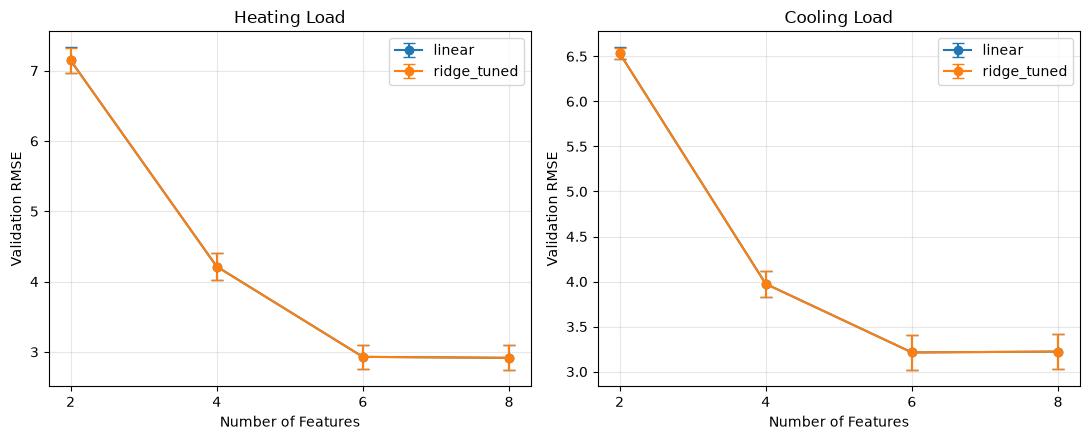

In [41]:
import matplotlib.pyplot as plt

summary = (
    all_ablation_df
    .groupby(["target", "model", "n_features"])["rmse"]
    .agg(["mean", "std"])
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, target in zip(axes, TARGET_COLUMNS):
    subset = summary[summary["target"] == target]

    for model_name in subset["model"].unique():
        model_data = subset[
            subset["model"] == model_name
        ].sort_values("n_features")

        ax.errorbar(
            model_data["n_features"],
            model_data["mean"],
            yerr=model_data["std"],
            marker="o",
            capsize=4,
            label=model_name,
        )

    ax.set_title(target.replace("_", " ").title())
    ax.set_xlabel("Number of Features")
    ax.set_ylabel("Validation RMSE")
    ax.set_xticks(FEATURE_COUNTS)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

figure_path = (
    project_root / "results" / "figures"
    / "linear_ridge_feature_ablation.png"
)

plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

### Discrete-feature sensitivity check

Recalculate mutual information while treating orientation and glazing-area distribution as discrete variables, then compare the resulting ranking.

In [42]:
from sklearn.feature_selection import mutual_info_regression

train_idx, _ = next(cv.split(X_dev))

X_train = X_dev.iloc[train_idx]
y_train = y_dev["heating_load"].iloc[train_idx]

discrete_mask = [
    column in ["orientation", "glazing_area_distribution"]
    for column in FEATURE_COLUMNS
]

mi_scores = mutual_info_regression(
    X_train,
    y_train,
    discrete_features=discrete_mask,
    random_state=42,
)

alternative_ranking = pd.Series(
    mi_scores,
    index=FEATURE_COLUMNS,
).sort_values(ascending=False)

alternative_ranking

surface_area                 1.514596
relative_compactness         1.510509
wall_area                    0.940012
roof_area                    0.863310
glazing_area                 0.660799
overall_height               0.643817
glazing_area_distribution    0.155956
orientation                  0.000000
dtype: float64